# Module 6 Lab 1: SQL Inside a Notebook

### Store Orders: Asking Business Questions with SQL

**Name:** Mac Mckay

**Course:** CS 82A

**Repo:** https://github.com/raulmckay-blip/cs82a-portfolio

## Overview

This project puts the store's orders and customers into a small database, answers some business questions with SQL, and turns one of the answers into a chart.

## Step 1: Load the CSVs and build the database

In [15]:
import sqlite3
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style='whitegrid')

orders_df = pd.read_csv('store_orders.csv')
customers_df = pd.read_csv('store_customers.csv')

print('orders:   ', orders_df.shape)      # 200 orders, 6 columns
print('customers:', customers_df.shape)   # 40 customers, 4 columns

orders:    (200, 6)
customers: (40, 4)


In [16]:
con = sqlite3.connect('store.db')

# if_exists='replace' so re-running the notebook doesn't crash on "table already exists"
orders_df.to_sql('orders', con, index=False, if_exists='replace')
customers_df.to_sql('customers', con, index=False, if_exists='replace')

pd.read_sql("SELECT name FROM sqlite_master", con)

,name
0,orders
1,customers


Both tables are in `store.db` now. I added `if_exists='replace'` because without it the second time I ran the cell it would error out saying the table already exists.

## Step 2: First look

In [17]:
pd.read_sql("SELECT * FROM orders LIMIT 5", con)

,order_id,customer_id,product,category,amount,order_date
0,5000,4,paper,office,14.09,2026-05-25
1,5001,15,planner,office,51.86,2026-05-08
2,5002,34,shelf,furniture,116.25,2026-06-03
3,5003,2,granola,snacks,19.72,2026-05-19
4,5004,17,monitor,electronics,284.80,2026-05-10


Every order has an id, the customer who placed it, the product, its category, the dollar amount, and the date.

## Step 3: Filter and sort

In [18]:
big_orders = pd.read_sql('''
    SELECT *
    FROM orders
    WHERE amount > 100
    ORDER BY amount DESC
''', con)

print('orders over $100:', len(big_orders))
big_orders.head(10)

orders over $100: 84


,order_id,customer_id,product,category,amount,order_date
0,5153,20,dock,electronics,499.00,2026-05-25
1,5140,30,headset,electronics,295.36,2026-05-26
2,5047,901,headset,electronics,293.79,2026-05-15
3,5150,903,monitor,electronics,293.35,2026-06-06
4,5014,6,monitor,electronics,287.83,2026-05-22
5,5113,4,headset,electronics,286.65,2026-05-15
6,5034,29,headset,electronics,286.36,2026-05-14
7,5149,8,headset,electronics,286.30,2026-05-05
8,5004,17,monitor,electronics,284.80,2026-05-10
9,5174,11,headset,electronics,277.24,2026-05-26


In [19]:
print('smallest amount:', big_orders['amount'].min())
print('sorted high to low:', big_orders['amount'].is_monotonic_decreasing)

smallest amount: 100.27
sorted high to low: True



84 of the 200 orders are over \$100. I only showed the top 10 so the notebook doesn't get too long.

## Step 4: Aggregate by category

In [20]:
pd.read_sql('''
    SELECT category,
           COUNT(*)    AS n,
           AVG(amount) AS avg_amount
    FROM orders
    GROUP BY category
    ORDER BY avg_amount DESC
''', con).round(2)

,category,n,avg_amount
0,electronics,60,190.57
1,furniture,46,146.25
2,office,51,30.13
3,snacks,43,14.62


Electronics earns the most per order at about \$191 on average.

## Step 5: Join for spend by city

In [21]:
city_spend = pd.read_sql('''
    SELECT c.city,
           COUNT(*)      AS n_orders,
           SUM(o.amount) AS total_spend
    FROM orders o
    JOIN customers c ON o.customer_id = c.customer_id
    GROUP BY c.city
    ORDER BY total_spend DESC
''', con).round(2)

city_spend

,city,n_orders,total_spend
0,Los Angeles,46,5862.99
1,Culver City,58,5316.88
2,Santa Monica,42,4017.93
3,Inglewood,27,2718.25
4,Torrance,14,1037.25
5,Venice,8,462.36


I joined the two tables on `customer_id` since that's the column both tables share.

## Step 6: The row-count audit

In [22]:
n_orders = pd.read_sql("SELECT COUNT(*) AS n FROM orders", con)['n'][0]

n_joined = pd.read_sql('''
    SELECT COUNT(*) AS n
    FROM orders o
    JOIN customers c ON o.customer_id = c.customer_id
''', con)['n'][0]

print('rows in orders:     ', n_orders)
print('rows after the join:', n_joined)
print('orders lost:        ', n_orders - n_joined)

rows in orders:      200
rows after the join: 195
orders lost:         5


In [23]:
# which orders didn't find a customer? (LEFT JOIN keeps them, the customer columns come back empty)
pd.read_sql('''
    SELECT o.*
    FROM orders o
    LEFT JOIN customers c ON o.customer_id = c.customer_id
    WHERE c.customer_id IS NULL
''', con)

,order_id,customer_id,product,category,amount,order_date
0,5012,900,planner,office,34.51,2026-05-24
1,5047,901,headset,electronics,293.79,2026-05-15
2,5099,902,pens,office,16.68,2026-05-01
3,5150,903,monitor,electronics,293.35,2026-06-06
4,5188,904,headset,electronics,273.16,2026-05-22


The orders table has 200 rows but the join only gave back 195...

The 5 missing orders have customer ids from 900 to 904, which don't exist in the customers table, so an inner join has nothing to match them with and drops them.

Note that is about \$911 of sales that don't show up in any city's total.

## Step 7: Chart a query result

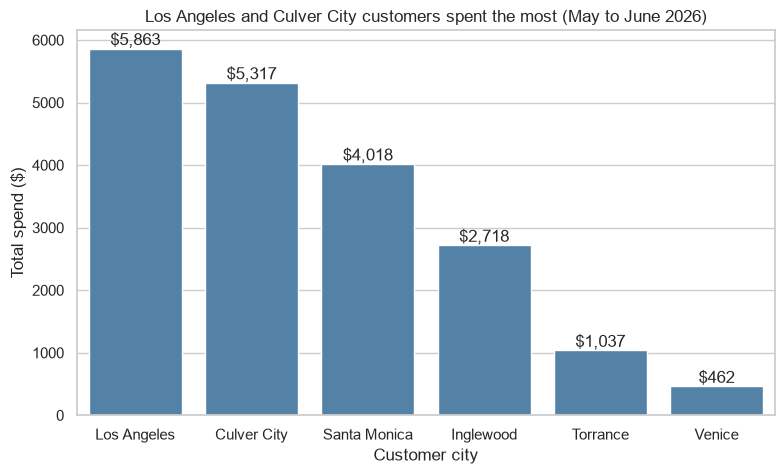

In [24]:
plt.figure(figsize=(9, 5))
ax = sns.barplot(data=city_spend, x='city', y='total_spend', color='steelblue')
ax.bar_label(ax.containers[0], fmt='${:,.0f}')
plt.title('Los Angeles and Culver City customers spent the most (May to June 2026)')
plt.xlabel('Customer city')
plt.ylabel('Total spend ($)')
plt.show()

The chart comes straight from the Step 5 query, so it's already sorted from highest to lowest.

## Step 8: My own question

**Question:** Which product brings in the most money?

In [25]:
pd.read_sql('''
    SELECT product,
           category,
           COUNT(*)    AS n_orders,
           SUM(amount) AS revenue
    FROM orders
    GROUP BY product, category
    ORDER BY revenue DESC
    LIMIT 5
''', con).round(2)

,product,category,n_orders,revenue
0,headset,electronics,23,4902.30
1,dock,electronics,20,3357.14
2,monitor,electronics,17,3174.73
3,shelf,furniture,19,3030.45
4,chair,furniture,17,2589.93


**Answer:** The headset brought in about \$4,902 from 23 orders. Funny enough the top 3 products are all electronics (headset, dock, monitor), which matches what was found in Step 4. 

Note: This is sales, not profit, since the data doesn't say what each item cost the store.

## Step 9: Ethics note

Before sharing this I'd remove the names and only show totals by city or category. I'd also watch out for small groups, like Venice with only 3 customers, since adding one more detail could point to one person. That's why I never print the customers table and keep `store.db` and `store_customers.csv` off GitHub.

In [26]:
con.close()

## AI Use

I used AI to help with syntax and refine wording on this lab.